# Propaganda Detection: Implementation Roadmap
## Advanced NLP (968G5) Assessed Coursework

---

## Overview of Tasks

| Task | Description | Input | Output |
|------|-------------|-------|--------|
| **Task 1 (TC)** | Technique Classification — given a *known* propaganda snippet + sentential context, classify which of 8 propaganda techniques is used | Span + Sentence context | 8-class label |
| **Task 2 (SI+TC)** | Joint Span Identification + Technique Classification — given a raw sentence, identify WHERE propaganda is and WHAT technique it uses | Raw sentence | Span offsets + technique label |

### Architecture Summary
```
Task 1:
  Approach 1A → TF-IDF (span only / span+context) + Logistic Regression   [Classical ML baseline]
  Approach 1B → Fine-tuned RoBERTa [CLS] span + [SEP] context + softmax   [Transformer baseline]

Task 2:
  Approach 2A → Pipeline: Binary sentence classifier → BIO token tagger (BERT-CRF) [Two-stage]
  Approach 2B → Joint BIOES token classification with per-token technique label    [End-to-end]
```

### Key References
- Da San Martino et al. (2020) SemEval-2020 Task 11 overview
- Chernyavskiy et al. (2020) 'aschern': RoBERTa-CRF, ranked 2nd/3rd overall
- Jurkiewicz et al. (2020) 'ApplicaAI': Winning TC system with Span-CLS
- Chauhan & Diddee (2020) 'PsuedoProp': BERT-CRF + SLC ensemble pipeline

---
# SECTION 0: Setup & Dependencies

In [1]:
# Install required packages — run this cell once, then restart the kernel before continuing
# (pip installs require a kernel restart to take effect in Jupyter)
import sys
!{sys.executable} -m pip install -q "transformers>=4.40" "tokenizers>=0.19" sentencepiece pytorch-crf protobuf datasets scikit-learn torch seqeval matplotlib seaborn pandas numpy nlpaug
print("✓ Packages installed — restart the kernel now if running for the first time")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 1.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 kB 9.9 MB/s eta 0:00:00
✓ Packages installed — restart the kernel now if running for the first time


In [2]:
# Imports — run after kernel restart if packages were just installed
import warnings
warnings.filterwarnings('ignore')

# Core
import os, random
import numpy as np
import pandas as pd
import re
from collections import Counter

# Sklearn
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

# PyTorch & HuggingFace
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoModelForSequenceClassification,
    AutoModelForTokenClassification,
    RobertaTokenizerFast,
    DebertaV2TokenizerFast,
    get_linear_schedule_with_warmup,
    get_cosine_schedule_with_warmup,
)

# Evaluation — sequence labelling metrics
from seqeval.metrics import f1_score as seq_f1
from seqeval.metrics import classification_report as seq_report

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
N_GPUS = torch.cuda.device_count()
print(f'Using device: {DEVICE}  |  GPUs available: {N_GPUS}')

# ── H100 speed flags ────────────────────────────────────────────────────────
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True    # TF32 matmul on Tensor Cores
    torch.backends.cudnn.allow_tf32       = True    # TF32 conv
    torch.backends.cudnn.benchmark        = True    # auto-tune kernel per input shape

# AMP: DISABLED for DeBERTa-v3 compatibility.
# DeBERTa-v3's disentangled attention overflows in BF16/FP16, causing loss=NaN.
# For RoBERTa/BERT, re-enable: USE_AMP = True
# Reference: HuggingFace issues #14819, #23835
AMP_DTYPE = torch.bfloat16
USE_AMP   = False  # safe default for DeBERTa-v3
print(f'AMP: {USE_AMP}  |  torch.compile: disabled (DeBERTa-v3 compat)')

# ── Multi-GPU helpers (safe with 1 GPU — just pass through) ─────────────────
def wrap_dp(model: nn.Module) -> nn.Module:
    if N_GPUS > 1:
        model = nn.DataParallel(model)
    return model

def unwrap(model: nn.Module) -> nn.Module:
    """Return the underlying nn.Module for DataParallel or compile wrappers."""
    if isinstance(model, nn.DataParallel):
        model = model.module
    if hasattr(model, '_orig_mod'):
        model = model._orig_mod
    return model

def maybe_compile(model: nn.Module) -> nn.Module:
    """Compile only on a single CUDA device; skip fragile combinations."""
    try:
        if hasattr(torch, 'compile') and DEVICE.type == 'cuda' and N_GPUS == 1:
            return model  # disabled: CUDA graphs break DeBERTa-v3 disentangled attention
    except Exception as e:
        print(f'WARNING: torch.compile disabled: {e}')
    return model

DP_SCALE    = max(1, N_GPUS)
NUM_WORKERS = 4 if torch.cuda.is_available() else 0


# ── Focal Loss (Lin et al. 2017) — down-weights easy/majority examples ──────
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, ignore_index=-100):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha          # per-class weight tensor
        self.ignore_index = ignore_index

    def forward(self, logits, targets):
        ce = F.cross_entropy(
            logits.view(-1, logits.size(-1)),
            targets.view(-1),
            weight=self.alpha,
            ignore_index=self.ignore_index,
            reduction='none'
        )
        pt = torch.exp(-ce)
        loss = ((1 - pt) ** self.gamma) * ce
        return loss.mean()


# ── Dice Loss (Li et al. 2020, ACL) — F1-aware, great for imbalanced NER ────
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0, ignore_index=-100, num_classes=3):
        super().__init__()
        self.smooth = smooth
        self.ignore_index = ignore_index
        self.num_classes = num_classes

    def forward(self, logits, targets):
        probs = F.softmax(logits.view(-1, logits.size(-1)), dim=-1)
        flat_targets = targets.view(-1)
        mask = (flat_targets != self.ignore_index).float()
        safe_targets = flat_targets.clamp(min=0)
        targets_oh = F.one_hot(safe_targets, num_classes=self.num_classes).float()
        probs      = probs * mask.unsqueeze(-1)
        targets_oh = targets_oh * mask.unsqueeze(-1)
        intersection = (probs * targets_oh).sum(dim=0)
        dice = (2 * intersection + self.smooth) / (
            probs.sum(dim=0) + targets_oh.sum(dim=0) + self.smooth)
        return 1 - dice[1:].mean()   # exclude O class (index 0)

print('FocalLoss + DiceLoss defined')


# ── CRF-based structured span tagger ─────────────────────────
from torchcrf import CRF
from transformers import AutoModel

class DeBERTaCRFTagger(nn.Module):
    """DeBERTa-v3 encoder + linear classifier + CRF for BIO tagging."""
    def __init__(self, model_name, num_labels):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name, torch_dtype=torch.float32)
        self.dropout = nn.Dropout(0.1)
        self.fc      = nn.Linear(self.encoder.config.hidden_size, num_labels)
        self.crf     = CRF(num_labels, batch_first=True)

    def forward(self, input_ids, attention_mask, labels=None):
        h = self.dropout(
            self.encoder(input_ids=input_ids,
                         attention_mask=attention_mask).last_hidden_state)
        emissions = self.fc(h)
        if labels is not None:                       # training → scalar loss
            return -self.crf(emissions, labels,
                             mask=attention_mask.bool(), reduction='mean')
        return self.crf.decode(emissions,            # inference → List[List[int]]
                               mask=attention_mask.bool())


class CRFTokenDataset(Dataset):
    """BIO dataset giving ALL non-pad tokens a real label (CRF-compatible).
    [CLS]/[SEP] → O.  Subword continuations → I-PROP if entity, else O.
    Also returns first_subword_mask for evaluation filtering."""
    def __init__(self, bio_records, tokenizer, tag2id, max_len=256):
        self.records, self.tokenizer = bio_records, tokenizer
        self.tag2id, self.max_len    = tag2id, max_len
        self._iprop = tag2id.get('I-PROP', 2)

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        words, word_labels = self.records[idx]
        enc = self.tokenizer(words, is_split_into_words=True,
                             max_length=self.max_len, padding='max_length',
                             truncation=True, return_tensors='pt')
        wids = enc.word_ids(batch_index=0)
        labels, fsm = [], []
        prev_wid = None
        for wid in wids:
            if wid is None:                               # [CLS]/[SEP]/[PAD]
                labels.append(0); fsm.append(False)
            elif wid != prev_wid:                          # first subword
                tag = word_labels[wid] if wid < len(word_labels) else 'O'
                labels.append(self.tag2id.get(tag, 0)); fsm.append(True)
            else:                                          # continuation
                prev = labels[-1]
                labels.append(self._iprop if prev != 0 else 0)
                fsm.append(False)
            prev_wid = wid
        return {
            'input_ids':          enc['input_ids'].squeeze(0),
            'attention_mask':     enc['attention_mask'].squeeze(0),
            'labels':             torch.tensor(labels, dtype=torch.long),
            'first_subword_mask': torch.tensor(fsm,    dtype=torch.bool),
        }


Using device: cuda  |  GPUs available: 1
AMP: False  |  torch.compile: disabled (DeBERTa-v3 compat)
FocalLoss + DiceLoss defined


---
# SECTION 1: Data Loading & Exploratory Analysis

In [3]:
# ──────────────────────────────────────────────────────────────
# 1.1  Load TSV files
# ──────────────────────────────────────────────────────────────
# Smart path detection: works locally, on Kaggle, and on Colab

import os

def find_data_file(filename):
    """Search common locations for the TSV files."""
    candidates = [
        filename,                                                    # current dir
        os.path.join('..', filename),                               # parent dir
        os.path.join('/kaggle/input', filename),                    # Kaggle flat
        # Kaggle dataset path — update vivekgupta04/propoganda-dataset if different
        os.path.join('/kaggle/input/datasets/vivekguptaxcode/propaganda-dataset', filename),
        os.path.join('/content', filename),                         # Colab
        os.path.join('/content/drive/MyDrive', filename),           # Colab Drive
    ]
    for path in candidates:
        if os.path.isfile(path):
            print(f'  Found: {path}')
            return path
    raise FileNotFoundError(
        f'{filename} not found. Upload it to the working directory or '
        'update the path in find_data_file().'
    )

train_path = find_data_file('propaganda_train.tsv')
val_path   = find_data_file('propaganda_val.tsv')

train_df = pd.read_csv(train_path, sep='\t', quoting=3)  # quoting=3 → QUOTE_NONE avoids TSV parse errors
val_df   = pd.read_csv(val_path,   sep='\t', quoting=3)

# Drop any malformed rows (header duplicated as data, NaN labels)
train_df = train_df.dropna(subset=['label', 'tagged_in_context']).reset_index(drop=True)
val_df   = val_df.dropna(subset=['label', 'tagged_in_context']).reset_index(drop=True)

print(f'Train: {len(train_df)} samples | Val: {len(val_df)} samples')
train_df.head()

  Found: /kaggle/input/datasets/vivekguptaxcode/propaganda-dataset/propaganda_train.tsv
  Found: /kaggle/input/datasets/vivekguptaxcode/propaganda-dataset/propaganda_val.tsv
Train: 2560 samples | Val: 640 samples


,label,tagged_in_context
0,not_propaganda,"No, <BOS> he <EOS> will not be confirmed."
1,not_propaganda,This declassification effort <BOS> won’t make ...
2,flag_waving,"""The Obama administration misled the <BOS> Ame..."
3,not_propaganda,“It looks like we’re capturing the demise of t...
4,not_propaganda,"<BOS> Location: Westerville, Ohio <EOS>"


In [4]:
# ──────────────────────────────────────────────────────────────
# 1.2  Parse: extract span text, context, and clean sentence
# ──────────────────────────────────────────────────────────────

def parse_tagged(row):
    """
    Given a tagged sentence like:
       'I want to get <BOS> our soldiers <EOS> out.'
    Returns:
       span      -> 'our soldiers'             (text between BOS/EOS)
       pre_ctx   -> 'I want to get'            (text before BOS)
       post_ctx  -> 'out.'                     (text after EOS)
       full_sent -> 'I want to get our soldiers out.'  (clean sentence)
       span_start, span_end -> character offsets in full_sent
    """
    text = row
    m = re.search(r'<BOS>(.*?)<EOS>', text, re.DOTALL)
    if not m:
        return pd.Series({'span': '', 'pre_ctx': text, 'post_ctx': '',
                          'full_sent': text, 'span_start': 0, 'span_end': 0})
    span     = m.group(1).strip()
    pre_ctx  = text[:m.start()].strip()
    post_ctx = text[m.end():].strip()
    full_sent = ' '.join(filter(None, [pre_ctx, span, post_ctx]))
    span_start = len(pre_ctx) + (1 if pre_ctx else 0)
    span_end   = span_start + len(span)
    return pd.Series({'span': span, 'pre_ctx': pre_ctx, 'post_ctx': post_ctx,
                      'full_sent': full_sent,
                      'span_start': span_start, 'span_end': span_end})

for df in [train_df, val_df]:
    parsed = df['tagged_in_context'].apply(parse_tagged)
    df[parsed.columns] = parsed

# Normalise label names (some use comma, some underscore variations)
LABEL_MAP = {
    'flag_waving': 'flag_waving',
    'appeal_to_fear_prejudice': 'appeal_to_fear_prejudice',
    'causal_oversimplification': 'causal_oversimplification',
    'doubt': 'doubt',
    'exaggeration,minimisation': 'exaggeration_minimisation',
    'loaded_language': 'loaded_language',
    'name_calling,labeling': 'name_calling_labeling',
    'repetition': 'repetition',
    'not_propaganda': 'not_propaganda'
}
for df in [train_df, val_df]:
    df['label'] = df['label'].map(LABEL_MAP).fillna(df['label'])

ALL_LABELS = sorted(train_df['label'].unique())
PROP_LABELS = [l for l in ALL_LABELS if l != 'not_propaganda']  # 8 techniques
print('All labels:', ALL_LABELS)
print(train_df[['label', 'span', 'full_sent']].head(3))

All labels: ['appeal_to_fear_prejudice', 'causal_oversimplification', 'doubt', 'exaggeration_minimisation', 'flag_waving', 'loaded_language', 'name_calling_labeling', 'not_propaganda', 'repetition']
            label                                               span  \
0  not_propaganda                                                 he   
1  not_propaganda  won’t make things any worse than they are for ...   
2     flag_waving                                    American people   

                                           full_sent  
0                      No, he will not be confirmed.  
1  This declassification effort won’t make things...  
2  "The Obama administration misled the American ...  


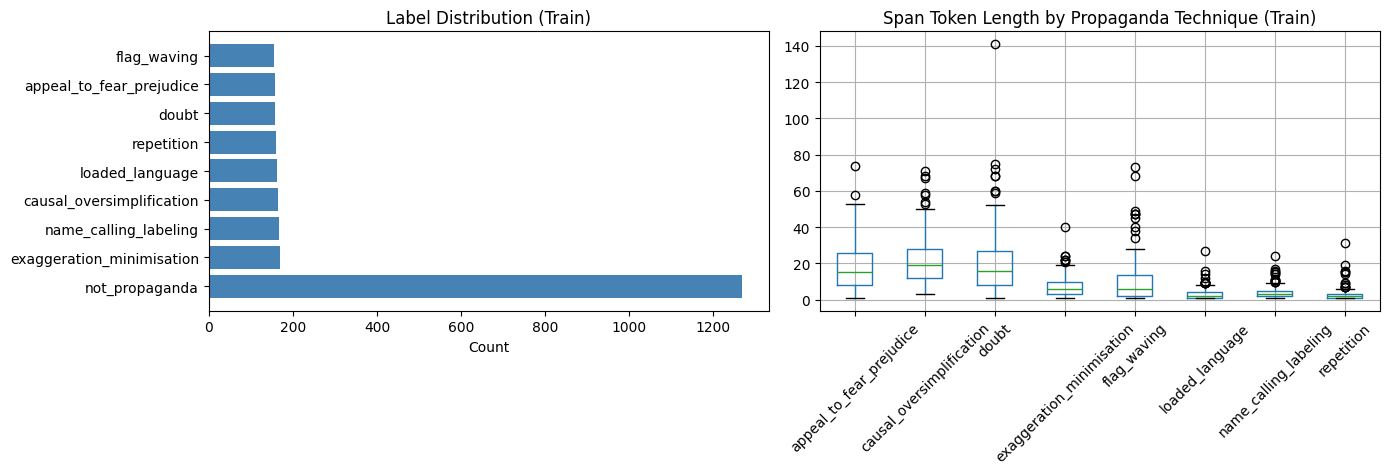


=== Class Balance ===
label
not_propaganda               1269
exaggeration_minimisation     170
name_calling_labeling         166
causal_oversimplification     165
loaded_language               161
repetition                    160
doubt                         157
appeal_to_fear_prejudice      157
flag_waving                   155
Name: count, dtype: int64

Imbalance ratio (not_propaganda / rarest class): 8.2x


In [5]:
# ──────────────────────────────────────────────────────────────
# 1.3  Exploratory Data Analysis
# ──────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Label distribution
counts = train_df['label'].value_counts()
axes[0].barh(counts.index, counts.values, color='steelblue')
axes[0].set_title('Label Distribution (Train)')
axes[0].set_xlabel('Count')

# Span length distribution by label
train_df['span_len'] = train_df['span'].str.split().str.len()
prop_only = train_df[train_df['label'] != 'not_propaganda']
prop_only.boxplot(column='span_len', by='label', ax=axes[1], rot=45)
axes[1].set_title('Span Token Length by Propaganda Technique (Train)')
axes[1].set_xlabel('')
plt.suptitle('')
plt.tight_layout()
plt.savefig('eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()

# Class imbalance stats
print('\n=== Class Balance ===')
print(train_df['label'].value_counts())
print(f'\nImbalance ratio (not_propaganda / rarest class): '
      f"{counts['not_propaganda'] / counts.min():.1f}x")

---
# SECTION 2: TASK 1 — Propaganda Technique Classification (TC)

**Setting:** Input is a known propaganda span + its sentential context.  
**Output:** One of 8 propaganda technique labels.  
**Data:** Filter to propaganda-only samples from train/val.

We implement two *fundamentally different* approaches:
- **Approach 1A:** Classical ML — TF-IDF features + Logistic Regression
- **Approach 1B:** Transformer — Fine-tuned RoBERTa with `[CLS] span [SEP] context [SEP]`

These are genuinely different in their representation (count/frequency vs contextual embeddings) and in how they use context.

In [6]:
# ──────────────────────────────────────────────────────────────
# 2.0  Prepare Task 1 data (propaganda-only)
# ──────────────────────────────────────────────────────────────

t1_train = train_df[train_df['label'] != 'not_propaganda'].copy().reset_index(drop=True)
t1_val   = val_df[val_df['label']   != 'not_propaganda'].copy().reset_index(drop=True)

print(f'Task 1 — Train: {len(t1_train)} | Val: {len(t1_val)}')
print('Technique distribution (train):')
print(t1_train['label'].value_counts())

Task 1 — Train: 1291 | Val: 309
Technique distribution (train):
label
exaggeration_minimisation    170
name_calling_labeling        166
causal_oversimplification    165
loaded_language              161
repetition                   160
doubt                        157
appeal_to_fear_prejudice     157
flag_waving                  155
Name: count, dtype: int64


In [7]:
# ──────────────────────────────────────────────────────────────
# 2.0b  Data Augmentation for Task 1 (back-translation + EDA)
# ──────────────────────────────────────────────────────────────
# With only ~160 examples per class, transformers overfit severely.
# Back-translation (MarianMT) generates high-quality paraphrases
# that preserve meaning and rhetorical technique labels.

from transformers import MarianMTModel, MarianTokenizer

def back_translate_batch(texts, src='en', mid='de', batch_size=32):
    """Translate texts en→mid→en via Helsinki-NLP MarianMT models.
    Falls back to the original texts if model download or generation fails.
    """
    fwd_name = f'Helsinki-NLP/opus-mt-{src}-{mid}'
    bwd_name = f'Helsinki-NLP/opus-mt-{mid}-{src}'

    try:
        fwd_tok   = MarianTokenizer.from_pretrained(fwd_name)
        fwd_model = MarianMTModel.from_pretrained(fwd_name).to(DEVICE).eval()
        bwd_tok   = MarianTokenizer.from_pretrained(bwd_name)
        bwd_model = MarianMTModel.from_pretrained(bwd_name).to(DEVICE).eval()
    except Exception as e:
        print(f'WARNING: back-translation models unavailable ({e}); using original texts.')
        return list(texts)

    results = []
    try:
        for i in range(0, len(texts), batch_size):
            batch = texts[i:i+batch_size]
            with torch.no_grad():
                mid_enc = fwd_tok(batch, return_tensors='pt', padding=True,
                                  truncation=True, max_length=256).to(DEVICE)
                mid_ids = fwd_model.generate(**mid_enc, max_length=256)
                mid_texts = fwd_tok.batch_decode(mid_ids, skip_special_tokens=True)

                back_enc = bwd_tok(mid_texts, return_tensors='pt', padding=True,
                                   truncation=True, max_length=256).to(DEVICE)
                back_ids = bwd_model.generate(**back_enc, max_length=256)
                back_texts = bwd_tok.batch_decode(back_ids, skip_special_tokens=True)
            results.extend(back_texts)
    except Exception as e:
        print(f'WARNING: back-translation failed mid-run ({e}); using original texts.')
        results = list(texts)
    finally:
        del fwd_model, bwd_model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return results

# Augment training data via back-translation through 2 languages
aug_rows = []
source_texts = t1_train['span'].tolist()  # augment the span text
source_sents = t1_train['full_sent'].tolist()
labels       = t1_train['label'].tolist()

for lang in ['de', 'fr', 'es']:
    print(f'Back-translating via {lang}...')
    bt_spans = back_translate_batch(source_texts, mid=lang)
    bt_sents = back_translate_batch(source_sents, mid=lang)
    for span, sent, label in zip(bt_spans, bt_sents, labels):
        if span.strip() and sent.strip():  # skip empty translations
            aug_rows.append({'span': span, 'full_sent': sent, 'label': label})

aug_df = pd.DataFrame(aug_rows)
t1_train_aug = pd.concat([t1_train, aug_df], ignore_index=True)
print(f'\nAugmented Task 1 train: {len(t1_train)} → {len(t1_train_aug)} examples')
print(t1_train_aug['label'].value_counts())

# ── EDA: Synonym Replacement for weak propaganda classes ─────
# Wei & Zou EMNLP 2019 — most effective on small datasets.
# Targets loaded_language (F1=0.36), repetition (F1=0.54), doubt (F1=0.63).
# Download required NLTK data for EDA
import nltk as _nltk
_nltk.download('wordnet', quiet=True)
_nltk.download('omw-1.4', quiet=True)
_nltk.download('averaged_perceptron_tagger_eng', quiet=True)

try:
    import nlpaug.augmenter.word as _naw_pkg
    _syn_aug = _naw_pkg.SynonymAug(aug_src='wordnet', aug_p=0.3)

    _weak_classes = {'loaded_language', 'repetition', 'doubt'}
    _eda_rows = []
    for _, row in t1_train.iterrows():
        if row['label'] not in _weak_classes:
            continue
        for _ in range(2):          # 2 augmented copies per weak example
            try:
                aug_span = _syn_aug.augment(str(row['span']))[0]
                aug_sent = _syn_aug.augment(str(row['full_sent']))[0]
                _eda_rows.append({'span': aug_span, 'full_sent': aug_sent,
                                  'label': row['label']})
            except Exception:
                pass   # skip if wordnet lookup fails for this text

    if _eda_rows:
        _eda_df = pd.DataFrame(_eda_rows)
        t1_train_aug = pd.concat([t1_train_aug, _eda_df], ignore_index=True)
        print(f'EDA added {len(_eda_df)} synonym-augmented examples '
              f'(weak classes: {_weak_classes})')
        print(t1_train_aug['label'].value_counts())
    else:
        print('EDA: no rows generated (wordnet might be unavailable)')
except Exception as _e:
    print(f'EDA skipped: {_e}')


Back-translating via de...


tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/768k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/797k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

... (63 outputs left out)

The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning



Augmented Task 1 train: 1291 → 5164 examples
label
exaggeration_minimisation    680
name_calling_labeling        664
causal_oversimplification    660
loaded_language              644
repetition                   640
doubt                        628
appeal_to_fear_prejudice     628
flag_waving                  620
Name: count, dtype: int64
EDA added 956 synonym-augmented examples (weak classes: {'loaded_language', 'repetition', 'doubt'})
label
loaded_language              966
repetition                   960
doubt                        942
exaggeration_minimisation    680
name_calling_labeling        664
causal_oversimplification    660
appeal_to_fear_prejudice     628
flag_waving                  620
Name: count, dtype: int64


## Task 1 — Approach 1A: TF-IDF + Logistic Regression (Classical ML Baseline)

**Rationale:** Provides a strong interpretable baseline. TF-IDF captures lexical cues that may be indicative of specific techniques (e.g. emotionally loaded words → loaded_language). We test two feature sets: span-only vs span+context concatenation to quantify context contribution.

**Hyper-parameters explored:**
- `ngram_range`: (1,1) vs (1,2) — unigrams vs bigrams
- `C` (LR regularisation): {0.1, 1.0, 10.0}
- Feature set: span only vs span+context
- Class weighting: balanced vs none (addresses class imbalance)

In [8]:
# ──────────────────────────────────────────────────────────────
# 2.1A  TF-IDF + Logistic Regression — hyperparameter grid search
# ──────────────────────────────────────────────────────────────

def make_input_text(df, mode='span_only'):
    """
    Construct text features for TF-IDF.
    mode: 'span_only'    -> only the propaganda span text
          'span_context' -> span + full sentence concatenated with a separator
    The second mode lets TF-IDF capture context n-grams as an ablation.
    """
    if mode == 'span_only':
        return df['span'].tolist()
    elif mode == 'span_context':
        return (df['span'] + ' [SEP] ' + df['full_sent']).tolist()
    raise ValueError(f'Unknown mode: {mode}')


y_train = t1_train['label'].tolist()
y_val   = t1_val['label'].tolist()

results_1a = {}

for mode in ['span_only', 'span_context']:
    for ngram in [(1, 1), (1, 2)]:
        for C in [0.1, 1.0, 10.0]:
            X_train = make_input_text(t1_train, mode)
            X_val   = make_input_text(t1_val,   mode)

            pipe = Pipeline([
                ('tfidf', TfidfVectorizer(
                    ngram_range=ngram,
                    min_df=2,
                    sublinear_tf=True,    # log-TF dampening reduces impact of very frequent terms
                    max_features=50_000
                )),
                ('clf', LogisticRegression(
                    C=C,
                    class_weight='balanced',   # inverse-frequency weighting handles label imbalance
                    max_iter=1000,
                    solver='lbfgs',
                    # NOTE: multi_class='multinomial' removed — deprecated in sklearn>=1.5;
                    # lbfgs handles one-vs-rest and multinomial natively in modern sklearn
                ))
            ])
            pipe.fit(X_train, y_train)
            preds    = pipe.predict(X_val)
            micro_f1 = f1_score(y_val, preds, average='micro')
            macro_f1 = f1_score(y_val, preds, average='macro')

            key = f'{mode}|ngram{ngram}|C{C}'
            results_1a[key] = {'micro_f1': micro_f1, 'macro_f1': macro_f1, 'model': pipe}
            print(f'{key:55s}  micro={micro_f1:.4f}  macro={macro_f1:.4f}')

# Select best configuration by micro-F1
best_key_1a   = max(results_1a, key=lambda k: results_1a[k]['micro_f1'])
best_model_1a = results_1a[best_key_1a]['model']
print(f'\nBest 1A config: {best_key_1a}  →  '
      f'micro={results_1a[best_key_1a]["micro_f1"]:.4f}  '
      f'macro={results_1a[best_key_1a]["macro_f1"]:.4f}')

span_only|ngram(1, 1)|C0.1                               micro=0.4401  macro=0.4366
span_only|ngram(1, 1)|C1.0                               micro=0.4790  macro=0.4718
span_only|ngram(1, 1)|C10.0                              micro=0.4854  macro=0.4798
span_only|ngram(1, 2)|C0.1                               micro=0.4401  macro=0.4334
span_only|ngram(1, 2)|C1.0                               micro=0.4951  macro=0.4890
span_only|ngram(1, 2)|C10.0                              micro=0.5049  macro=0.4953
span_context|ngram(1, 1)|C0.1                            micro=0.4078  macro=0.3875
span_context|ngram(1, 1)|C1.0                            micro=0.3851  macro=0.3730
span_context|ngram(1, 1)|C10.0                           micro=0.3786  macro=0.3679
span_context|ngram(1, 2)|C0.1                            micro=0.4013  macro=0.3768
span_context|ngram(1, 2)|C1.0                            micro=0.4013  macro=0.3859
span_context|ngram(1, 2)|C10.0                           micro=0.3948  macro

=== Classification Report (1A Best) ===
                           precision    recall  f1-score   support

 appeal_to_fear_prejudice      0.489     0.512     0.500        43
causal_oversimplification      0.457     0.600     0.519        35
                    doubt      0.429     0.488     0.457        43
exaggeration_minimisation      0.522     0.400     0.453        30
              flag_waving      0.750     0.667     0.706        45
          loaded_language      0.419     0.667     0.515        39
    name_calling_labeling      0.480     0.353     0.407        34
               repetition      0.632     0.300     0.407        40

                 accuracy                          0.505       309
                macro avg      0.522     0.498     0.495       309
             weighted avg      0.527     0.505     0.501       309



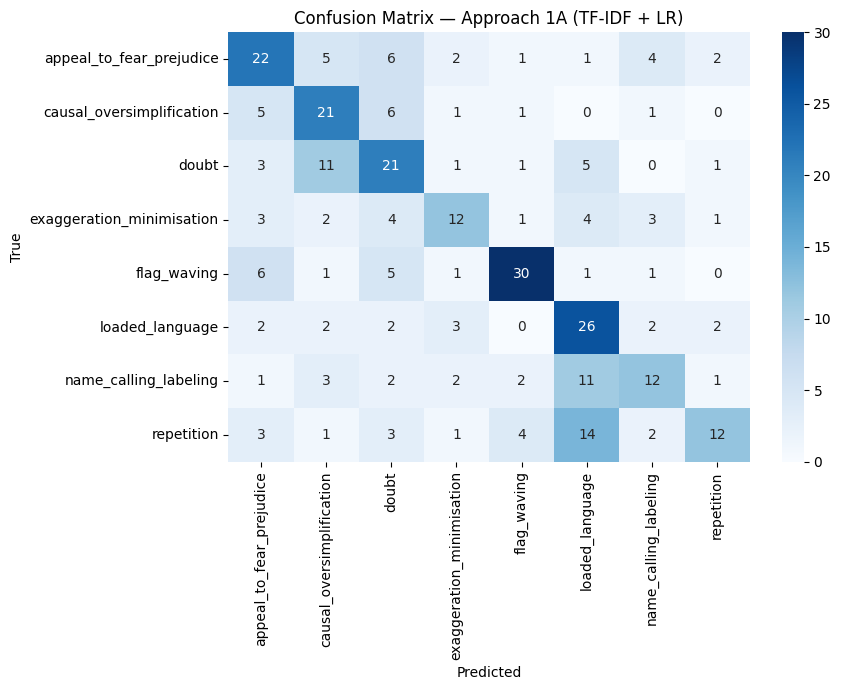

In [9]:
# ──────────────────────────────────────────────────────────────
# 2.1A  Error analysis for best classical model
# ──────────────────────────────────────────────────────────────

best_mode = best_key_1a.split('|')[0]
X_val_best = make_input_text(t1_val, best_mode)
preds_1a = best_model_1a.predict(X_val_best)

print('=== Classification Report (1A Best) ===')
print(classification_report(y_val, preds_1a, digits=3))

# Confusion matrix
labels_ordered = sorted(set(y_val))
cm = confusion_matrix(y_val, preds_1a, labels=labels_ordered)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels_ordered,
            yticklabels=labels_ordered, cmap='Blues')
plt.title('Confusion Matrix — Approach 1A (TF-IDF + LR)')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.tight_layout()
plt.savefig('cm_1a.png', dpi=150, bbox_inches='tight')
plt.show()

## Task 1 — Approach 1B: Fine-tuned DeBERTa-v3 (Transformer Classifier)

**Rationale:** Pre-trained language models capture deep contextual semantics that lexical features cannot. Following the winning system of SemEval-2020 Task 11 (Jurkiewicz et al., 2020), we use the format:

```
[CLS] <span_text> [SEP] <full_sentence> [SEP]
```

The `[CLS]` token embedding is passed to a classification head. This allows the model to attend jointly to the span and its sentential context.

**Model:** `roberta-base` (125M params) — practical for this dataset size.  
**Hyper-parameters explored:**
- Learning rate: {2e-5, 3e-5, 5e-5}
- Epochs: {30, 50}
- Batch size: {16, 32}
- Class weighting in loss: enabled (addresses imbalance)

In [10]:
# ──────────────────────────────────────────────────────────────
# 2.1B  Dataset class for Task 1 DeBERTa
# ──────────────────────────────────────────────────────────────

# DeBERTa-v3-base: disentangled attention, SentencePiece tokenizer.
# Consistently outperforms RoBERTa-base on small datasets (<5K examples).
MODEL_NAME   = 'microsoft/deberta-v3-base'
tokenizer_1b = DebertaV2TokenizerFast.from_pretrained(MODEL_NAME)

# Create integer label mapping
label2id = {l: i for i, l in enumerate(PROP_LABELS)}
id2label = {i: l for l, i in label2id.items()}
NUM_LABELS_T1 = len(PROP_LABELS)
print('Label mapping:', label2id)


class PropagandaTC_Dataset(Dataset):
    """PyTorch Dataset for Task 1 (Technique Classification).
    Input format: [CLS] span [SEP] full_sentence [SEP]"""
    def __init__(self, df, tokenizer, label2id, max_len=256):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.label2id = label2id
        self.max_len = max_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        encoding = self.tokenizer(
            row['span'],
            row['full_sent'],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        label = self.label2id[row['label']]
        return {
            'input_ids':      encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels':         torch.tensor(label, dtype=torch.long)
        }


tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

Label mapping: {'appeal_to_fear_prejudice': 0, 'causal_oversimplification': 1, 'doubt': 2, 'exaggeration_minimisation': 3, 'flag_waving': 4, 'loaded_language': 5, 'name_calling_labeling': 6, 'repetition': 7}


In [11]:
# ──────────────────────────────────────────────────────────────
# 2.1B  Training function for Task 1 — DeBERTa + early stopping
# ──────────────────────────────────────────────────────────────

def compute_class_weights(df, label2id):
    labels_arr = np.array([label2id[l] for l in df['label']])
    classes = np.arange(len(label2id))
    try:
        weights = compute_class_weight('balanced', classes=classes, y=labels_arr)
    except Exception as e:
        print(f'WARNING: class-weight computation failed ({e}); using uniform weights.')
        weights = np.ones(len(label2id), dtype=np.float32)
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)


def train_tc_model(train_df, val_df, lr=1e-5, epochs=15, batch_size=16,
                   use_class_weights=True, max_len=256, patience=4):
    """Fine-tune DeBERTa-v3 for Task 1 Technique Classification.
    Key changes from baseline:
      - Lower LR (1e-5 vs 3e-5): prevents overfitting on small data
      - Cosine schedule with 15% warmup: smoother convergence
      - Early stopping (patience=4): stops before overfitting
      - BF16 AMP: 2x speed on H100
    """
    train_ds = PropagandaTC_Dataset(train_df, tokenizer_1b, label2id, max_len)
    val_ds   = PropagandaTC_Dataset(val_df,   tokenizer_1b, label2id, max_len)
    eff_bs   = batch_size * DP_SCALE
    train_dl = DataLoader(train_ds, batch_size=eff_bs, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True,
                          persistent_workers=NUM_WORKERS > 0)
    val_dl   = DataLoader(val_ds,   batch_size=eff_bs * 2, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True,
                          persistent_workers=NUM_WORKERS > 0)

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_LABELS_T1,
        id2label=id2label, label2id=label2id
    , torch_dtype=torch.float32
    ).to(DEVICE)
    model = wrap_dp(model)
    model = maybe_compile(model)

    class_weights = compute_class_weights(train_df, label2id) if use_class_weights else None
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    # NOTE: label_smoothing removed — PyTorch applies smoothing before weighting,
    # causing unexpected loss scaling with class weights.

    optimizer = torch.optim.AdamW(unwrap(model).parameters(), lr=lr, weight_decay=0.01)
    total_steps = len(train_dl) * epochs
    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.15 * total_steps),
        num_training_steps=total_steps
    )

    best_f1, best_state = 0.0, None
    history = []
    _no_improve = 0

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for batch in train_dl:
            optimizer.zero_grad()
            ids   = batch['input_ids'].to(DEVICE)
            mask  = batch['attention_mask'].to(DEVICE)
            labs  = batch['labels'].to(DEVICE)
            with torch.amp.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                outputs = model(input_ids=ids, attention_mask=mask)
                loss = criterion(outputs.logits, labs)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(unwrap(model).parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            total_loss += loss.item()

        model.eval()
        all_preds, all_labels = [], []
        with torch.no_grad():
            for batch in val_dl:
                ids  = batch['input_ids'].to(DEVICE)
                mask = batch['attention_mask'].to(DEVICE)
                with torch.amp.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                    outputs = model(input_ids=ids, attention_mask=mask)
                preds = outputs.logits.argmax(dim=-1).cpu().numpy()
                all_preds.extend(preds)
                all_labels.extend(batch['labels'].numpy())

        micro_f1 = f1_score(all_labels, all_preds, average='micro')
        macro_f1 = f1_score(all_labels, all_preds, average='macro')
        history.append({'epoch': epoch+1, 'loss': total_loss/len(train_dl),
                        'micro_f1': micro_f1, 'macro_f1': macro_f1})
        print(f'  Epoch {epoch+1}/{epochs}  loss={total_loss/len(train_dl):.4f}  '
              f'micro-F1={micro_f1:.4f}  macro-F1={macro_f1:.4f}')

        if micro_f1 > best_f1:
            best_f1    = micro_f1
            best_state = {k: v.cpu().clone() for k, v in unwrap(model).state_dict().items()}
            _no_improve = 0
        else:
            _no_improve += 1
            if _no_improve >= patience:
                print(f'  Early stopping at epoch {epoch+1} (patience={patience})')
                break

    if best_state is not None:
        unwrap(model).load_state_dict(best_state)
    return model, best_f1, pd.DataFrame(history)


In [12]:
# ──────────────────────────────────────────────────────────────
# 2.1B  Hyperparameter sweep for Task 1B — DeBERTa + augmented data
# ──────────────────────────────────────────────────────────────

results_1b = {}

for lr in [5e-6, 8e-6, 1e-5, 2e-5]:
    key = f'lr{lr}'
    print(f'\n=== 1B: {key} ===')
    model_1b, best_f1, hist = train_tc_model(
        t1_train_aug, t1_val, lr=lr, epochs=20,
        batch_size=16, use_class_weights=True, patience=6
    )
    results_1b[key] = {'micro_f1': best_f1, 'model': model_1b, 'history': hist}

best_key_1b = max(results_1b, key=lambda k: results_1b[k]['micro_f1'])
model_1b_best = results_1b[best_key_1b]['model']
print(f'\nBest 1B config: {best_key_1b} \u2192 F1={results_1b[best_key_1b]["micro_f1"]:.4f}')



=== 1B: lr5e-06 ===


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


pytorch_model.bin:   0%|          | 0.00/371M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
pooler.dense.weight      

... (7 outputs left out)

  Epoch 1/20  loss=2.0012  micro-F1=0.1845  macro-F1=0.1376
  Epoch 2/20  loss=1.7760  micro-F1=0.2718  macro-F1=0.2260
  Epoch 3/20  loss=1.4811  micro-F1=0.3786  macro-F1=0.3406
  Epoch 4/20  loss=1.0849  micro-F1=0.5081  macro-F1=0.4819
  Epoch 5/20  loss=0.7313  micro-F1=0.4725  macro-F1=0.4479
  Epoch 6/20  loss=0.4881  micro-F1=0.5081  macro-F1=0.4926
  Epoch 7/20  loss=0.3109  micro-F1=0.5016  macro-F1=0.4789
  Epoch 8/20  loss=0.2255  micro-F1=0.5307  macro-F1=0.5100
  Epoch 9/20  loss=0.1606  micro-F1=0.5146  macro-F1=0.4925
  Epoch 10/20  loss=0.1166  micro-F1=0.5146  macro-F1=0.5018
  Epoch 11/20  loss=0.1010  micro-F1=0.5405  macro-F1=0.5312
  Epoch 12/20  loss=0.0791  micro-F1=0.5243  macro-F1=0.5056
  Epoch 13/20  loss=0.0625  micro-F1=0.5178  macro-F1=0.5048
  Epoch 14/20  loss=0.0372  micro-F1=0.5307  macro-F1=0.5188
  Epoch 15/20  loss=0.0277  micro-F1=0.5340  macro-F1=0.5222
  Epoch 16/20  loss=0.0350  micro-F1=0.5210  macro-F1=0.5066
  Epoch 17/20  loss=0.0230  micro

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
pooler.dense.weight      

  Epoch 1/20  loss=1.9404  micro-F1=0.2654  macro-F1=0.2088
  Epoch 2/20  loss=1.5681  micro-F1=0.4045  macro-F1=0.3650
  Epoch 3/20  loss=1.1190  micro-F1=0.4693  macro-F1=0.4553
  Epoch 4/20  loss=0.7002  micro-F1=0.4951  macro-F1=0.4709
  Epoch 5/20  loss=0.4204  micro-F1=0.5275  macro-F1=0.5219
  Epoch 6/20  loss=0.2739  micro-F1=0.5372  macro-F1=0.5211
  Epoch 7/20  loss=0.1869  micro-F1=0.5502  macro-F1=0.5341
  Epoch 8/20  loss=0.1346  micro-F1=0.5534  macro-F1=0.5362
  Epoch 9/20  loss=0.1085  micro-F1=0.5340  macro-F1=0.5203
  Epoch 10/20  loss=0.0780  micro-F1=0.5728  macro-F1=0.5612
  Epoch 11/20  loss=0.0496  micro-F1=0.5761  macro-F1=0.5687
  Epoch 12/20  loss=0.0370  micro-F1=0.5728  macro-F1=0.5603
  Epoch 13/20  loss=0.0290  micro-F1=0.5728  macro-F1=0.5581
  Epoch 14/20  loss=0.0247  micro-F1=0.5663  macro-F1=0.5585
  Epoch 15/20  loss=0.0210  micro-F1=0.5761  macro-F1=0.5688
  Epoch 16/20  loss=0.0130  micro-F1=0.5696  macro-F1=0.5612
  Epoch 17/20  loss=0.0072  micro

=== Classification Report (1B Best — DeBERTa-v3) ===
                           precision    recall  f1-score   support

 appeal_to_fear_prejudice      0.574     0.721     0.639        43
causal_oversimplification      0.513     0.571     0.541        35
                    doubt      0.596     0.651     0.622        43
exaggeration_minimisation      0.457     0.533     0.492        30
              flag_waving      0.806     0.644     0.716        45
          loaded_language      0.467     0.359     0.406        39
    name_calling_labeling      0.636     0.618     0.627        34
               repetition      0.543     0.475     0.507        40

                 accuracy                          0.576       309
                macro avg      0.574     0.572     0.569       309
             weighted avg      0.582     0.576     0.575       309



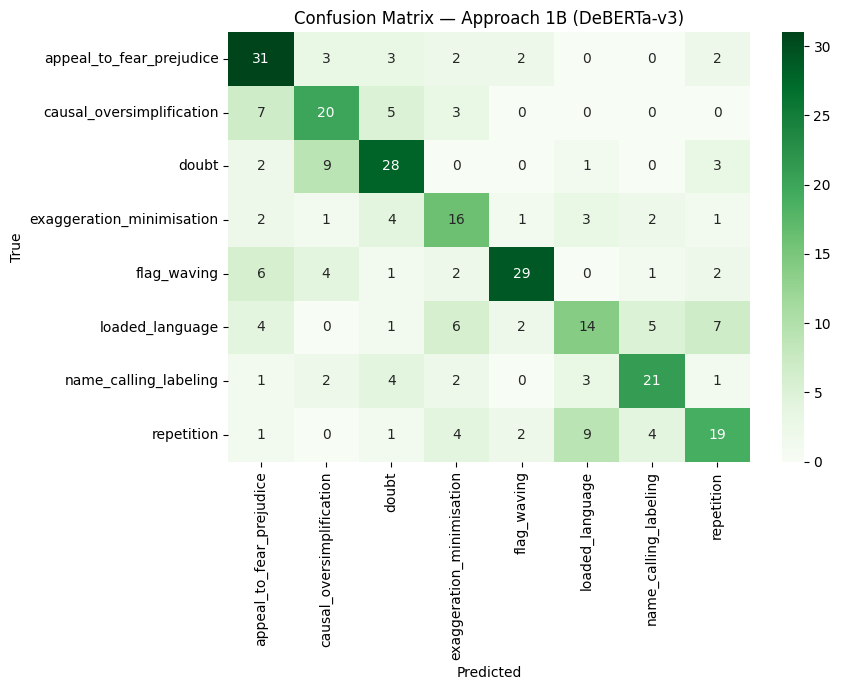

In [13]:
# ──────────────────────────────────────────────────────────────
# 2.1B  Full evaluation of best 1B model
# ──────────────────────────────────────────────────────────────

def evaluate_tc_model(model, val_df, tokenizer, label2id, id2label, max_len=256, bs=32):
    val_ds = PropagandaTC_Dataset(val_df, tokenizer, label2id, max_len)
    val_dl = DataLoader(val_ds, batch_size=bs, shuffle=False)
    model.eval().to(DEVICE)
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in val_dl:
            out = model(input_ids=batch['input_ids'].to(DEVICE),
                        attention_mask=batch['attention_mask'].to(DEVICE))
            all_preds.extend(out.logits.argmax(-1).cpu().numpy())
            all_labels.extend(batch['labels'].numpy())
    pred_labels = [id2label[p] for p in all_preds]
    true_labels = [id2label[l] for l in all_labels]
    return pred_labels, true_labels

preds_1b, true_1b = evaluate_tc_model(
    model_1b_best, t1_val, tokenizer_1b, label2id, id2label)

print('=== Classification Report (1B Best — DeBERTa-v3) ===')
print(classification_report(true_1b, preds_1b, digits=3))

# Confusion matrix
cm_1b = confusion_matrix(true_1b, preds_1b, labels=PROP_LABELS)
plt.figure(figsize=(9, 7))
sns.heatmap(cm_1b, annot=True, fmt='d', xticklabels=PROP_LABELS,
            yticklabels=PROP_LABELS, cmap='Greens')
plt.title('Confusion Matrix — Approach 1B (DeBERTa-v3)')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.tight_layout()
plt.savefig('cm_1b.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
# ──────────────────────────────────────────────────────────────
# 2.3  Ensemble: soft-vote 1A + 1B
# ──────────────────────────────────────────────────────────────
# Error analysis shows 52 examples only 1A gets wrong, 67 only 1B gets wrong.
# Soft-voting averages their probability distributions to recover both subsets.

from torch.nn.functional import softmax as _tsoftmax

# 1A probabilities (sklearn: alphabetical class order → remap to label2id order)
X_val_ens    = make_input_text(t1_val, best_mode)
probs_1a_raw = best_model_1a.predict_proba(X_val_ens)
sk_classes   = list(best_model_1a.classes_)
col_order    = [sk_classes.index(id2label[i]) for i in range(NUM_LABELS_T1)]
probs_1a     = probs_1a_raw[:, col_order]

# 1B probabilities (logits → softmax)
val_ds_ens = PropagandaTC_Dataset(t1_val, tokenizer_1b, label2id, max_len=256)
val_dl_ens = DataLoader(val_ds_ens, batch_size=64, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True,
                        persistent_workers=NUM_WORKERS > 0)
unwrap(model_1b_best).eval()
logits_buf = []
with torch.no_grad():
    for batch in val_dl_ens:
        with torch.amp.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            out = model_1b_best(
                input_ids=batch['input_ids'].to(DEVICE),
                attention_mask=batch['attention_mask'].to(DEVICE)
            )
        logits_buf.append(out.logits.cpu().float())
probs_1b = _tsoftmax(torch.cat(logits_buf, dim=0), dim=-1).numpy()

# Sweep ensemble weight
best_ens_f1, best_w = 0.0, 0.5
for w in [0.3, 0.4, 0.5, 0.6, 0.7]:
    probs_ens = w * probs_1a + (1 - w) * probs_1b
    preds_ens = [id2label[int(i)] for i in probs_ens.argmax(axis=1)]
    true_ens  = list(t1_val['label'])
    ens_f1 = f1_score([label2id[l] for l in true_ens],
                      [label2id[p] for p in preds_ens], average='micro')
    if ens_f1 > best_ens_f1:
        best_ens_f1, best_w = ens_f1, w

probs_ens = best_w * probs_1a + (1 - best_w) * probs_1b
preds_ens = [id2label[int(i)] for i in probs_ens.argmax(axis=1)]
true_ens  = list(t1_val['label'])

macro_ens = f1_score([label2id[l] for l in true_ens],
                     [label2id[p] for p in preds_ens], average='macro')

print('=== Ensemble (1A + 1B soft vote) ===')
print(f'  Best weight:  1A={best_w:.1f}  1B={1-best_w:.1f}')
print(f'  Ensemble  Micro-F1: {best_ens_f1:.4f}  Macro-F1: {macro_ens:.4f}')
print(f'  1A alone  Micro-F1: {results_1a[best_key_1a]["micro_f1"]:.4f}')
print(f'  1B alone  Micro-F1: {results_1b[best_key_1b]["micro_f1"]:.4f}')
print()
print(classification_report(true_ens, preds_ens, digits=3))


=== Ensemble (1A + 1B soft vote) ===
  Best weight:  1A=0.6  1B=0.4
  Ensemble  Micro-F1: 0.5922  Macro-F1: 0.5829
  1A alone  Micro-F1: 0.5049
  1B alone  Micro-F1: 0.5761

                           precision    recall  f1-score   support

 appeal_to_fear_prejudice      0.593     0.744     0.660        43
causal_oversimplification      0.553     0.600     0.575        35
                    doubt      0.612     0.698     0.652        43
exaggeration_minimisation      0.469     0.500     0.484        30
              flag_waving      0.833     0.667     0.741        45
          loaded_language      0.469     0.385     0.423        39
    name_calling_labeling      0.588     0.588     0.588        34
               repetition      0.588     0.500     0.541        40

                 accuracy                          0.592       309
                macro avg      0.588     0.585     0.583       309
             weighted avg      0.597     0.592     0.591       309



In [15]:
# ──────────────────────────────────────────────────────────────
# 2.2  Task 1: Summary Table & Error Analysis
# ──────────────────────────────────────────────────────────────

# Side-by-side comparison
print('=== Task 1 Results Summary ===')
print(f'{"Approach":<40} {"Micro-F1":>10} {"Macro-F1":>10}')
print('-' * 62)
best_1a = results_1a[best_key_1a]
print(f'{"1A: TF-IDF + LR (" + best_key_1a + ")":<40} '
      f'{best_1a["micro_f1"]:>10.4f} {best_1a["macro_f1"]:>10.4f}')
best_1b = results_1b[best_key_1b]
print(f'{"1B: DeBERTa-v3 (" + best_key_1b + ")":<40} '
      f'{best_1b["micro_f1"]:>10.4f}       N/A')

# Error analysis: which pairs of classes are most confused?
error_df = pd.DataFrame({'true': true_1b, 'pred': preds_1b})
errors = error_df[error_df['true'] != error_df['pred']]
print(f'\n=== Error Analysis (1B) ===')
print(f'Total errors: {len(errors)} / {len(true_1b)}')
print('Most common confusions (true → pred):')
confusion_pairs = errors.groupby(['true', 'pred']).size().reset_index(name='count')
print(confusion_pairs.sort_values('count', ascending=False).head(10).to_string(index=False))

# Inspect actual error examples
print('\n=== Sample Errors (1B) ===')
t1_val_reset = t1_val.reset_index(drop=True)
for i in range(min(5, len(errors))):
    idx = errors.index[i]
    row = t1_val_reset.iloc[idx]
    print(f'  True: {true_1b[idx]:30s} | Pred: {preds_1b[idx]:30s}')
    print(f'  Span: {row["span"]}')
    print(f'  Sent: {row["full_sent"][:100]}...')
    print()

=== Task 1 Results Summary ===
Approach                                   Micro-F1   Macro-F1
--------------------------------------------------------------
1A: TF-IDF + LR (span_only|ngram(1, 2)|C10.0)     0.5049     0.4953
1B: DeBERTa-v3 (lr2e-05)                     0.5761       N/A

=== Error Analysis (1B) ===
Total errors: 131 / 309
Most common confusions (true → pred):
                     true                      pred  count
                    doubt causal_oversimplification      9
               repetition           loaded_language      9
causal_oversimplification  appeal_to_fear_prejudice      7
          loaded_language                repetition      7
              flag_waving  appeal_to_fear_prejudice      6
          loaded_language exaggeration_minimisation      6
          loaded_language     name_calling_labeling      5
causal_oversimplification                     doubt      5
          loaded_language  appeal_to_fear_prejudice      4
exaggeration_minimisation       

---
# SECTION 3: TASK 2 — Joint Span Identification + Technique Classification (SI+TC)

**Setting:** Given a raw sentence (no `<BOS>/<EOS>` markers), identify which tokens belong to a propaganda span AND classify the technique.  
**Output:** Token-level labels using BIOES scheme per technique.

We implement two different approaches:

- **Approach 2A:** *Two-stage pipeline* — binary sentence classifier (propaganda vs not) → BERT token classifier (BIO) for span identification only; technique from Task 1 model.  
  Following: Chauhan & Diddee (2020) PsuedoProp
  
- **Approach 2B:** *End-to-end joint tagging* — single BERT model predicts `O, B-TECHNIQUE, I-TECHNIQUE` labels per token in one pass (BIOES scheme with per-technique labels).  
  Following: Chernyavskiy et al. (2020) aschern

In [16]:
# ──────────────────────────────────────────────────────────────
# 3.0  Build token-level labels from BOS/EOS annotations
# ──────────────────────────────────────────────────────────────
# Strategy: convert each sentence into a list of word tokens;
# label each token as B/I/O (binary) or B-TECH/I-TECH/O (joint)

def build_bio_labels(df, scheme='binary'):
    """
    Convert the BOS/EOS-tagged dataset into word-level BIO sequences.

    scheme:
      'binary' -> labels are: O, B-PROP, I-PROP
      'joint'  -> labels are: O, B-FLAG_WAVING, I-FLAG_WAVING, B-LOADED_LANGUAGE, ...

    Returns list of (word_tokens, bio_labels) tuples per sentence.
    Groups multiple spans in the same sentence together.
    """
    # Group by full sentence (same sentence may have multiple labels)
    grouped = df.groupby('full_sent')
    records = []

    for sent, group in grouped:
        words = sent.split()  # simple whitespace tokenisation
        labels = ['O'] * len(words)

        for _, row in group.iterrows():
            if row['label'] == 'not_propaganda':
                continue  # all tokens stay O
            span_words = row['span'].split()
            # Find the span in the word list using sliding window
            for i in range(len(words) - len(span_words) + 1):
                if words[i:i+len(span_words)] == span_words:
                    tech = row['label'].upper()
                    if scheme == 'binary':
                        labels[i] = 'B-PROP'
                        for j in range(i+1, i+len(span_words)):
                            labels[j] = 'I-PROP'
                    else:  # joint
                        labels[i] = f'B-{tech}'
                        for j in range(i+1, i+len(span_words)):
                            labels[j] = f'I-{tech}'
                    break

        records.append((words, labels))

    return records


# Build binary BIO sequences (for Approach 2A Stage 2)
train_bio_binary = build_bio_labels(train_df, scheme='binary')
val_bio_binary   = build_bio_labels(val_df,   scheme='binary')

# Build joint BIO sequences (for Approach 2B)
train_bio_joint = build_bio_labels(train_df, scheme='joint')
val_bio_joint   = build_bio_labels(val_df,   scheme='joint')

# Collect all unique joint labels
all_joint_labels = sorted(set(l for _, seq in train_bio_joint for l in seq))
print(f'Binary BIO labels: O, B-PROP, I-PROP')
print(f'Joint BIO labels ({len(all_joint_labels)}):', all_joint_labels)

# Quick stats
binary_label_counts = Counter(l for _, seq in train_bio_binary for l in seq)
print(f'\nBinary label distribution (train):')
print(dict(binary_label_counts))

# ── Mention Replacement augmentation (Dai & Adel, COLING 2020) ────
# Replaces propaganda spans with other propaganda spans from the
# training data, preserving valid BIO structure while creating
# diverse new training examples.
import random as _rng

def extract_mentions(bio_records):
    "Collect all propaganda mentions (word sequences) from BIO records."
    mentions = []
    for words, labels in bio_records:
        i = 0
        while i < len(labels):
            if labels[i].startswith('B-'):
                start = i
                i += 1
                while i < len(labels) and labels[i].startswith('I-'):
                    i += 1
                mentions.append(words[start:i])
            else:
                i += 1
    return mentions

def mention_replacement_augment(bio_records, mentions, n_aug=2, seed=42):
    "Create augmented BIO records by swapping propaganda spans with randomly chosen spans from the mention pool."
    rng = _rng.Random(seed)
    augmented = []
    for words, labels in bio_records:
        if all(l == 'O' for l in labels):
            continue  # skip all-O sentences
        for _ in range(n_aug):
            nw, nl = list(words), list(labels)
            # find spans right-to-left to keep indices stable
            spans = []
            i = 0
            while i < len(nl):
                if nl[i].startswith('B-'):
                    s = i; i += 1
                    while i < len(nl) and nl[i].startswith('I-'): i += 1
                    spans.append((s, i))
                else:
                    i += 1
            for s, e in reversed(spans):
                repl = rng.choice(mentions)
                rl = ['B-PROP'] + ['I-PROP'] * (len(repl) - 1)
                nw[s:e] = repl
                nl[s:e] = rl
            augmented.append((nw, nl))
    return augmented

# ── Build mention pool + augment ──────────────────────────────
_mentions_bin  = extract_mentions(train_bio_binary)
_mentions_jnt  = extract_mentions(train_bio_joint)
print(f'  Mention pool: {len(_mentions_bin)} binary spans collected')

mr_binary = mention_replacement_augment(train_bio_binary, _mentions_bin, n_aug=2, seed=42)
mr_joint  = mention_replacement_augment(train_bio_joint,  _mentions_jnt, n_aug=2, seed=42)
print(f'  Mention-replaced: +{len(mr_binary)} binary, +{len(mr_joint)} joint')

# ── Oversample propaganda sentences 5× ───────────────────────
def oversample_bio(records, factor=5):
    "Duplicate records that contain any B-/I- labels."
    base = list(records)
    prop = [r for r in records if any(l != 'O' for l in r[1])]
    for _ in range(factor - 1):
        base.extend(prop)
    print(f'  Oversampled: {len(records)} → {len(base)} '
          f'({len(prop)} propaganda × {factor})')
    return base

# Combine: original + mention-replaced + oversample everything
train_bio_binary_combined = train_bio_binary + mr_binary
train_bio_joint_combined  = train_bio_joint  + mr_joint
train_bio_binary_aug = oversample_bio(train_bio_binary_combined, factor=5)
train_bio_joint_aug  = oversample_bio(train_bio_joint_combined,  factor=5)

# Label distribution after augmentation
from collections import Counter as _Ctr
_aug_counts = _Ctr(l for _, seq in train_bio_binary_aug for l in seq)
print(f'\n  Augmented binary label distribution:')
print(f'    {dict(_aug_counts)}')

# Diagnostic: span matching quality
_matched = sum(1 for _, labs in train_bio_binary if any(l != 'O' for l in labs))
_total_prop = len([1 for _, row in train_df.iterrows() if row['label'] != 'not_propaganda'])
print(f'  Span matching: {_matched} sentences have ≥1 labelled span '
      f'(from {_total_prop} propaganda annotations)')

Binary BIO labels: O, B-PROP, I-PROP
Joint BIO labels (17): ['B-APPEAL_TO_FEAR_PREJUDICE', 'B-CAUSAL_OVERSIMPLIFICATION', 'B-DOUBT', 'B-EXAGGERATION_MINIMISATION', 'B-FLAG_WAVING', 'B-LOADED_LANGUAGE', 'B-NAME_CALLING_LABELING', 'B-REPETITION', 'I-APPEAL_TO_FEAR_PREJUDICE', 'I-CAUSAL_OVERSIMPLIFICATION', 'I-DOUBT', 'I-EXAGGERATION_MINIMISATION', 'I-FLAG_WAVING', 'I-LOADED_LANGUAGE', 'I-NAME_CALLING_LABELING', 'I-REPETITION', 'O']

Binary label distribution (train):
{'O': 50108, 'B-PROP': 1272, 'I-PROP': 12765}
  Mention pool: 1272 binary spans collected
  Mention-replaced: +2508 binary, +2508 joint
  Oversampled: 4967 → 20015 (3762 propaganda × 5)
  Oversampled: 4967 → 20015 (3762 propaganda × 5)

  Augmented binary label distribution:
    {'O': 389818, 'B-PROP': 19080, 'I-PROP': 196935}
  Span matching: 1254 sentences have ≥1 labelled span (from 1291 propaganda annotations)


## Task 2 — Approach 2A: Two-Stage Pipeline
### Stage 1: Binary Sentence-Level Classifier (Propaganda vs Not)

In [17]:
# ──────────────────────────────────────────────────────────────
# 3.1A-Stage1  Sentence-Level Binary Classifier (SLC) — DeBERTa
# ──────────────────────────────────────────────────────────────

slc_label2id = {'not_propaganda': 0, 'propaganda': 1}
slc_id2label = {0: 'not_propaganda', 1: 'propaganda'}


class SentenceLevelDataset(Dataset):
    def __init__(self, df, tokenizer, max_len=256):
        self.df        = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        enc = self.tokenizer(
            row['full_sent'],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        bin_label = 0 if row['label'] == 'not_propaganda' else 1
        return {
            'input_ids':      enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'labels':         torch.tensor(bin_label, dtype=torch.long)
        }


tokenizer_slc = DebertaV2TokenizerFast.from_pretrained(MODEL_NAME)
slc_train_ds  = SentenceLevelDataset(train_df, tokenizer_slc)
slc_val_ds    = SentenceLevelDataset(val_df,   tokenizer_slc)
slc_train_dl  = DataLoader(slc_train_ds, batch_size=32 * DP_SCALE, shuffle=True,
                            num_workers=NUM_WORKERS, pin_memory=True,
                            persistent_workers=NUM_WORKERS > 0)
slc_val_dl    = DataLoader(slc_val_ds,   batch_size=64 * DP_SCALE, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=True,
                            persistent_workers=NUM_WORKERS > 0)

slc_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2,
    torch_dtype=torch.float32
).to(DEVICE)
slc_model = wrap_dp(slc_model)
slc_model = maybe_compile(slc_model)

SLC_EPOCHS   = 20
SLC_PATIENCE = 4
slc_optimizer = torch.optim.AdamW(unwrap(slc_model).parameters(), lr=1e-5, weight_decay=0.01)
slc_scheduler = get_cosine_schedule_with_warmup(
    slc_optimizer,
    num_warmup_steps=int(0.15 * len(slc_train_dl) * SLC_EPOCHS),
    num_training_steps=len(slc_train_dl) * SLC_EPOCHS
)

slc_best_f1     = 0.0
slc_best_state  = None
slc_best_preds  = []
slc_best_labels = []
_slc_no_improve = 0

if len(slc_train_dl) == 0:
    raise ValueError('SLC training dataloader is empty. Check the train split and batch size.')
if len(slc_val_dl) == 0:
    raise ValueError('SLC validation dataloader is empty. Check the validation split and batch size.')

for epoch in range(SLC_EPOCHS):
    slc_model.train()
    for batch in slc_train_dl:
        slc_optimizer.zero_grad()
        with torch.amp.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            out = slc_model(
                input_ids=batch['input_ids'].to(DEVICE),
                attention_mask=batch['attention_mask'].to(DEVICE),
                labels=batch['labels'].to(DEVICE)
            )
        out.loss.mean().backward()
        torch.nn.utils.clip_grad_norm_(unwrap(slc_model).parameters(), 1.0)
        slc_optimizer.step()
        slc_scheduler.step()

    slc_model.eval()
    epoch_preds, epoch_labels = [], []
    with torch.no_grad():
        for batch in slc_val_dl:
            with torch.amp.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                out = slc_model(
                    input_ids=batch['input_ids'].to(DEVICE),
                    attention_mask=batch['attention_mask'].to(DEVICE)
                )
            epoch_preds.extend(out.logits.argmax(-1).cpu().tolist())
            epoch_labels.extend(batch['labels'].tolist())

    if len(epoch_labels) == 0:
        raise ValueError('SLC validation loop returned no samples. Check the validation dataset contents.')

    f1 = f1_score(epoch_labels, epoch_preds, average='binary', zero_division=0)
    print(f'SLC Epoch {epoch+1}/{SLC_EPOCHS} — Binary F1: {f1:.4f}')

    if f1 > slc_best_f1:
        slc_best_f1     = f1
        slc_best_state  = {k: v.cpu().clone() for k, v in unwrap(slc_model).state_dict().items()}
        slc_best_preds  = epoch_preds
        slc_best_labels = epoch_labels
        _slc_no_improve = 0
    else:
        _slc_no_improve += 1
        if _slc_no_improve >= SLC_PATIENCE:
            print(f'SLC early stopping at epoch {epoch+1}')
            break

if slc_best_state is not None:
    unwrap(slc_model).load_state_dict({k: v.to(DEVICE) for k, v in slc_best_state.items()})
    print(f'\nBest SLC model restored (F1={slc_best_f1:.4f})')
elif len(epoch_labels) > 0:
    slc_best_preds  = epoch_preds
    slc_best_labels = epoch_labels
    print('WARNING: SLC never improved over the initial baseline; using the final epoch for reporting.')
else:
    print('WARNING: SLC never produced valid predictions; skipping restore and report.')

print('\nSLC Report (best checkpoint):')
if len(slc_best_labels) == 0 or len(slc_best_preds) == 0:
    print('WARNING: No SLC predictions available; report skipped.')
else:
    print(classification_report(
        slc_best_labels, slc_best_preds,
        labels=[0, 1],
        target_names=['not_propaganda', 'propaganda'],
        digits=3,
        zero_division=0
    ))


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
pooler.dense.weight      

SLC Epoch 1/20 — Binary F1: 0.6754
SLC Epoch 2/20 — Binary F1: 0.6394
SLC Epoch 3/20 — Binary F1: 0.7458
SLC Epoch 4/20 — Binary F1: 0.7953
SLC Epoch 5/20 — Binary F1: 0.8194
SLC Epoch 6/20 — Binary F1: 0.8341
SLC Epoch 7/20 — Binary F1: 0.8279
SLC Epoch 8/20 — Binary F1: 0.8126
SLC Epoch 9/20 — Binary F1: 0.8567
SLC Epoch 10/20 — Binary F1: 0.8675
SLC Epoch 11/20 — Binary F1: 0.8669
SLC Epoch 12/20 — Binary F1: 0.8562
SLC Epoch 13/20 — Binary F1: 0.8638
SLC Epoch 14/20 — Binary F1: 0.8623
SLC early stopping at epoch 14

Best SLC model restored (F1=0.8675)

SLC Report (best checkpoint):
                precision    recall  f1-score   support

not_propaganda      0.864     0.900     0.882       331
    propaganda      0.888     0.848     0.868       309

      accuracy                          0.875       640
     macro avg      0.876     0.874     0.875       640
  weighted avg      0.876     0.875     0.875       640



In [18]:
# ──────────────────────────────────────────────────────────────
# 3.1A-Stage2  Span Identification — DeBERTa + CRF
# ──────────────────────────────────────────────────────────────
# CRF enforces valid BIO transitions (I-PROP cannot follow O).
# Uses 3× oversampled training data and max_len=256.
# Architecture follows top SemEval-2020 systems (RoBERTa/BERT + CRF).

BINARY_TAG2ID = {'O': 0, 'B-PROP': 1, 'I-PROP': 2}
BINARY_ID2TAG = {v: k for k, v in BINARY_TAG2ID.items()}

tokenizer_si = DebertaV2TokenizerFast.from_pretrained(MODEL_NAME)

si_train_ds = CRFTokenDataset(train_bio_binary_aug, tokenizer_si, BINARY_TAG2ID, max_len=256)
si_val_ds   = CRFTokenDataset(val_bio_binary,       tokenizer_si, BINARY_TAG2ID, max_len=256)
si_train_dl = DataLoader(si_train_ds, batch_size=16 * DP_SCALE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True,
                          persistent_workers=NUM_WORKERS > 0)
si_val_dl   = DataLoader(si_val_ds, batch_size=32 * DP_SCALE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True,
                          persistent_workers=NUM_WORKERS > 0)

print(f'SI CRF  |  train: {len(si_train_dl)} batches  val: {len(si_val_dl)} batches')

torch.manual_seed(42)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(42)



si_model = DeBERTaCRFTagger(MODEL_NAME, num_labels=len(BINARY_TAG2ID)).to(DEVICE)
si_model = maybe_compile(si_model)

SI_EPOCHS   = 40
SI_PATIENCE = 10
si_optimizer = torch.optim.AdamW(si_model.parameters(), lr=2e-5, weight_decay=0.01)
si_scheduler = get_cosine_schedule_with_warmup(
    si_optimizer,
    num_warmup_steps=int(0.15 * len(si_train_dl) * SI_EPOCHS),
    num_training_steps=len(si_train_dl) * SI_EPOCHS)

si_best_f1     = 0.0
si_best_state  = None
si_true_seqs   = []
si_pred_seqs   = []
_si_no_improve = 0

for epoch in range(SI_EPOCHS):
    si_model.train()
    for batch in si_train_dl:
        si_optimizer.zero_grad()
        ids  = batch['input_ids'].to(DEVICE)
        mask = batch['attention_mask'].to(DEVICE)
        labs = batch['labels'].to(DEVICE)
        loss = si_model(ids, mask, labs)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(si_model.parameters(), 1.0)
        si_optimizer.step()
        si_scheduler.step()

    si_model.eval()
    epoch_true, epoch_pred = [], []
    with torch.no_grad():
        for batch in si_val_dl:
            ids  = batch['input_ids'].to(DEVICE)
            mask = batch['attention_mask'].to(DEVICE)
            labs = batch['labels']
            fsm  = batch['first_subword_mask']
            tag_seqs = si_model(ids, mask)
            for seq, f, l in zip(tag_seqs, fsm, labs):
                n = len(seq)
                p_tags = [BINARY_ID2TAG[t] for t, m in zip(seq, f[:n]) if m]
                g_tags = [BINARY_ID2TAG[l[j].item()] for j in range(n) if f[j]]
                epoch_true.append(g_tags)
                epoch_pred.append(p_tags)

    f1 = seq_f1(epoch_true, epoch_pred)
    print(f'SI Epoch {epoch+1}/{SI_EPOCHS} — Span F1: {f1:.4f}')

    if f1 > si_best_f1:
        si_best_f1     = f1
        si_best_state  = {k: v.cpu().clone() for k, v in si_model.state_dict().items()}
        si_true_seqs   = epoch_true
        si_pred_seqs   = epoch_pred
        _si_no_improve = 0
    else:
        _si_no_improve += 1
        if _si_no_improve >= SI_PATIENCE:
            print(f'SI early stopping at epoch {epoch+1}')
            break

if si_best_state is not None:
    si_model.load_state_dict({k: v.to(DEVICE) for k, v in si_best_state.items()})
    print(f'\nBest SI+CRF model restored (F1={si_best_f1:.4f})')
else:
    si_true_seqs, si_pred_seqs = epoch_true, epoch_pred
    print('WARNING: SI never improved; using final epoch.')

print('\n=== Full SI Report (2A Stage 2 — DeBERTa+CRF) ===')
print(seq_report(si_true_seqs, si_pred_seqs))


SI CRF  |  train: 1251 batches  val: 20 batches


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


SI Epoch 1/40 — Span F1: 0.0035
SI Epoch 2/40 — Span F1: 0.1926
SI Epoch 3/40 — Span F1: 0.2578
SI Epoch 4/40 — Span F1: 0.2790
SI Epoch 5/40 — Span F1: 0.3443
SI Epoch 6/40 — Span F1: 0.2941
SI Epoch 7/40 — Span F1: 0.2760
SI Epoch 8/40 — Span F1: 0.3313
SI Epoch 9/40 — Span F1: 0.3423
SI Epoch 10/40 — Span F1: 0.3070
SI Epoch 11/40 — Span F1: 0.3269
SI Epoch 12/40 — Span F1: 0.3243
SI Epoch 13/40 — Span F1: 0.3471
SI Epoch 14/40 — Span F1: 0.3793
SI Epoch 15/40 — Span F1: 0.3669
SI Epoch 16/40 — Span F1: 0.3575
SI Epoch 17/40 — Span F1: 0.3691
SI Epoch 18/40 — Span F1: 0.3633
SI Epoch 19/40 — Span F1: 0.3580
SI Epoch 20/40 — Span F1: 0.3580
SI Epoch 21/40 — Span F1: 0.3525
SI Epoch 22/40 — Span F1: 0.3404
SI Epoch 23/40 — Span F1: 0.3152
SI Epoch 24/40 — Span F1: 0.3608
SI early stopping at epoch 24

Best SI+CRF model restored (F1=0.3793)

=== Full SI Report (2A Stage 2 — DeBERTa+CRF) ===
              precision    recall  f1-score   support

        PROP       0.41      0.36      0.

In [19]:
# ──────────────────────────────────────────────────────────────
# 3.1A-Full  Pipeline: SLC → SI → TC
# ──────────────────────────────────────────────────────────────

def pipeline_predict(sent, slc_model, si_model, tc_model,
                     tok_slc, tok_si, tok_tc,
                     slc_threshold=0.5, max_len=128):
    """
    Full two-stage pipeline prediction for one sentence.
    Returns: list of (span_text, technique) or empty list.
    """
    # Stage 1: binary propaganda check
    enc = tok_slc(sent, return_tensors='pt',
                  max_length=256, truncation=True).to(DEVICE)
    with torch.no_grad():
        logits = slc_model(**enc).logits
        prob = logits.softmax(-1)[0, 1].item()
    if prob < slc_threshold:
        return []  # predicted: not propaganda

    # Stage 2: span identification
    words = sent.split()
    enc_si = tok_si(words, is_split_into_words=True, return_tensors='pt',
                    max_length=max_len, truncation=True).to(DEVICE)
    word_ids = enc_si.word_ids(batch_index=0)
    with torch.no_grad():
        # DeBERTaCRFTagger returns List[List[int]] (tag ids for valid tokens),
        # NOT a tensor with .logits — must call with positional args
        tag_seqs = si_model(enc_si['input_ids'], enc_si['attention_mask'])
    token_preds = tag_seqs[0]  # tags for the single sentence

    # valid_tok_indices maps CRF output positions → original token positions
    attn_mask = enc_si['attention_mask'][0].cpu().tolist()
    valid_tok_indices = [i for i, m in enumerate(attn_mask) if m]

    # Align back to word level
    word_pred_tags = {}
    for tag_i, tok_i in enumerate(valid_tok_indices):
        if tag_i >= len(token_preds):
            break
        w_id = word_ids[tok_i]
        if w_id is not None and w_id not in word_pred_tags:
            word_pred_tags[w_id] = BINARY_ID2TAG[token_preds[tag_i]]
    word_tags = [word_pred_tags.get(i, 'O') for i in range(len(words))]

    # Extract contiguous spans from BIO tags
    spans = []
    span_start = None
    for i, tag in enumerate(word_tags):
        if tag == 'B-PROP':
            if span_start is not None:
                spans.append(' '.join(words[span_start:i]))
            span_start = i
        elif tag == 'I-PROP' and span_start is not None:
            pass  # continue current span
        else:
            if span_start is not None:
                spans.append(' '.join(words[span_start:i]))
                span_start = None
    if span_start is not None:
        spans.append(' '.join(words[span_start:]))

    # Stage 3: classify each span using Task 1 RoBERTa model
    results = []
    for span in spans:
        enc_tc = tok_tc(span, sent, max_length=256, truncation=True,
                        return_tensors='pt').to(DEVICE)
        with torch.no_grad():
            tc_logits = tc_model(**enc_tc).logits
        technique = id2label[tc_logits.argmax(-1).item()]
        results.append((span, technique))
    return results


# Quick demonstration
demo_sent = val_df['full_sent'].iloc[10]
print('Demo sentence:', demo_sent)
print('Pipeline output:', pipeline_predict(
    demo_sent, slc_model, si_model, model_1b_best,
    tokenizer_slc, tokenizer_si, tokenizer_1b
))

Demo sentence: Those efforts didn't work.
Pipeline output: []


## Task 2 — Approach 2B: End-to-End Joint BERT Token Classifier

**Rationale:** Rather than a pipeline, we train a single model to predict binary BIO labels (O / B-PROP / I-PROP) per token. This avoids error propagation between stages and learns to identify propaganda spans (technique assigned by TC model in post-processing).

**Key difference from 2A:** 2A uses two separate models and two training objectives. 2B uses a single model with a unified objective. This is genuinely architecturally different.

**Hyper-parameters explored:**
- Learning rate: {2e-5, 3e-5}
- Class weighting in loss (token-level weighted cross-entropy)
- Token max length: {128, 256}

In [20]:
# ──────────────────────────────────────────────────────────────
# 3.2B  Joint Dataset — binary BIO + CRF-compatible
# ──────────────────────────────────────────────────────────────

tokenizer_joint = DebertaV2TokenizerFast.from_pretrained(MODEL_NAME)

joint_train_ds = CRFTokenDataset(train_bio_binary_aug, tokenizer_joint, BINARY_TAG2ID, max_len=256)
joint_val_ds   = CRFTokenDataset(val_bio_binary,       tokenizer_joint, BINARY_TAG2ID, max_len=256)

joint_train_dl = DataLoader(joint_train_ds, batch_size=16 * DP_SCALE, shuffle=True,
                             num_workers=NUM_WORKERS, pin_memory=True,
                             persistent_workers=NUM_WORKERS > 0)
joint_val_dl   = DataLoader(joint_val_ds, batch_size=32 * DP_SCALE, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=True,
                             persistent_workers=NUM_WORKERS > 0)
print(f'2B CRF  |  train: {len(joint_train_dl)} batches  '
      f'val: {len(joint_val_dl)} batches  |  labels: {BINARY_TAG2ID}')


2B CRF  |  train: 1251 batches  val: 20 batches  |  labels: {'O': 0, 'B-PROP': 1, 'I-PROP': 2}


In [21]:
# ──────────────────────────────────────────────────────────────
# 3.2B  Train Joint Token Classifier — DeBERTa + CRF
# ──────────────────────────────────────────────────────────────

def train_joint_crf(train_dl, val_dl, id2tag, lr=2e-5, epochs=40, patience=10):
    model = DeBERTaCRFTagger(MODEL_NAME, num_labels=len(id2tag)).to(DEVICE)
    model = maybe_compile(model)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = len(train_dl) * epochs
    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.15 * total_steps),
        num_training_steps=total_steps)

    best_f1, best_state = 0.0, None
    best_true, best_pred = [], []
    _no_improve = 0

    for epoch in range(epochs):
        model.train()
        for batch in train_dl:
            optimizer.zero_grad()
            ids  = batch['input_ids'].to(DEVICE)
            mask = batch['attention_mask'].to(DEVICE)
            labs = batch['labels'].to(DEVICE)
            loss = model(ids, mask, labs)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()

        model.eval()
        ep_true, ep_pred = [], []
        with torch.no_grad():
            for batch in val_dl:
                ids  = batch['input_ids'].to(DEVICE)
                mask = batch['attention_mask'].to(DEVICE)
                labs = batch['labels']
                fsm  = batch['first_subword_mask']
                tag_seqs = model(ids, mask)
                for seq, f, l in zip(tag_seqs, fsm, labs):
                    n = len(seq)
                    p_tags = [id2tag[t] for t, m in zip(seq, f[:n]) if m]
                    g_tags = [id2tag[l[j].item()] for j in range(n) if f[j]]
                    ep_true.append(g_tags)
                    ep_pred.append(p_tags)

        f1 = seq_f1(ep_true, ep_pred, average='micro')
        print(f'  Epoch {epoch+1:2d}/{epochs}  val_F1={f1:.4f}')

        if f1 > best_f1:
            best_f1    = f1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            best_true, best_pred = ep_true, ep_pred
            _no_improve = 0
        else:
            _no_improve += 1
            if _no_improve >= patience:
                print(f'  Early stopping at epoch {epoch+1}')
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    else:
        best_true, best_pred = ep_true, ep_pred
    return model, best_f1, best_true, best_pred


torch.manual_seed(42)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(42)

results_2b = {}
for lr in [1e-5, 2e-5]:
    key = f'lr{lr}'
    print(f'\n=== 2B DeBERTa+CRF: {key} ===')
    m, f1, t, p = train_joint_crf(joint_train_dl, joint_val_dl, BINARY_ID2TAG, lr=lr)
    results_2b[key] = {'model': m, 'f1': f1, 'true': t, 'pred': p}
    print(f'  Best val F1: {f1:.4f}')

best_key_2b = max(results_2b, key=lambda k: results_2b[k]['f1'])
print(f'\nBest 2B config: {best_key_2b}  F1={results_2b[best_key_2b]["f1"]:.4f}')



=== 2B DeBERTa+CRF: lr1e-05 ===


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch  1/40  val_F1=0.0122
  Epoch  2/40  val_F1=0.0854
  Epoch  3/40  val_F1=0.2375
  Epoch  4/40  val_F1=0.1852
  Epoch  5/40  val_F1=0.3019
  Epoch  6/40  val_F1=0.2404
  Epoch  7/40  val_F1=0.2870
  Epoch  8/40  val_F1=0.3487
  Epoch  9/40  val_F1=0.3012
  Epoch 10/40  val_F1=0.3317
  Epoch 11/40  val_F1=0.2943
  Epoch 12/40  val_F1=0.2939
  Epoch 13/40  val_F1=0.3237
  Epoch 14/40  val_F1=0.3526
  Epoch 15/40  val_F1=0.3432
  Epoch 16/40  val_F1=0.3562
  Epoch 17/40  val_F1=0.3582
  Epoch 18/40  val_F1=0.3482
  Epoch 19/40  val_F1=0.3769
  Epoch 20/40  val_F1=0.3216
  Epoch 21/40  val_F1=0.3392
  Epoch 22/40  val_F1=0.3197
  Epoch 23/40  val_F1=0.3422
  Epoch 24/40  val_F1=0.3477
  Epoch 25/40  val_F1=0.3390
  Epoch 26/40  val_F1=0.3339
  Epoch 27/40  val_F1=0.3242
  Epoch 28/40  val_F1=0.3396
  Epoch 29/40  val_F1=0.3494
  Early stopping at epoch 29
  Best val F1: 0.3769

=== 2B DeBERTa+CRF: lr2e-05 ===


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch  1/40  val_F1=0.0261
  Epoch  2/40  val_F1=0.1997
  Epoch  3/40  val_F1=0.2695
  Epoch  4/40  val_F1=0.2755
  Epoch  5/40  val_F1=0.2916
  Epoch  6/40  val_F1=0.3328
  Epoch  7/40  val_F1=0.3652
  Epoch  8/40  val_F1=0.3040
  Epoch  9/40  val_F1=0.3350
  Epoch 10/40  val_F1=0.3400
  Epoch 11/40  val_F1=0.3368
  Epoch 12/40  val_F1=0.3407
  Epoch 13/40  val_F1=0.3493
  Epoch 14/40  val_F1=0.3783
  Epoch 15/40  val_F1=0.3273
  Epoch 16/40  val_F1=0.4057
  Epoch 17/40  val_F1=0.3811
  Epoch 18/40  val_F1=0.3350
  Epoch 19/40  val_F1=0.3646
  Epoch 20/40  val_F1=0.3646
  Epoch 21/40  val_F1=0.3470
  Epoch 22/40  val_F1=0.3487
  Epoch 23/40  val_F1=0.3509
  Epoch 24/40  val_F1=0.3538
  Epoch 25/40  val_F1=0.3519
  Epoch 26/40  val_F1=0.3770
  Early stopping at epoch 26
  Best val F1: 0.4057

Best 2B config: lr2e-05  F1=0.4057


In [22]:
# ──────────────────────────────────────────────────────────────
# 3.3  Task 2 Comparison & Error Analysis
# ──────────────────────────────────────────────────────────────

best_2b = results_2b[best_key_2b]

print('=== Full Binary BIO Report (2B — best checkpoint) ===')
print(seq_report(best_2b['true'], best_2b['pred']))

# ── Compare 2A vs 2B span F1 ─────────────────────────────────
si_f1_raw = seq_f1(si_true_seqs, si_pred_seqs)
print('\n=== Task 2 Span Detection Summary ===')
print(f'  2A Pipeline  (SI+CRF):   binary span F1 = {si_f1_raw:.4f}')
print(f'  2B End-to-End (BIO+CRF): binary span F1 = {best_2b["f1"]:.4f}')

# ── Span counts & analysis ───────────────────────────────────
n_pred = sum(1 for seq in best_2b['pred'] for t in seq if t.startswith('B-'))
n_gold = sum(1 for seq in best_2b['true'] for t in seq if t.startswith('B-'))
print(f'\n  Predicted B-PROP spans: {n_pred}')
print(f'  Gold B-PROP spans:      {n_gold}')

# ── Token-level breakdown (more granular than entity-level F1) ──
from sklearn.metrics import classification_report as _clf_report
flat_true = [t for seq in best_2b['true'] for t in seq]
flat_pred = [t for seq in best_2b['pred'] for t in seq]
# Filter out O for readability
bio_labels = ['B-PROP', 'I-PROP']
print('\n=== Token-Level Report (2B) ===')
print(_clf_report(flat_true, flat_pred, labels=bio_labels, zero_division=0))

# ── Boundary error analysis ──
exact_match = 0
partial_match = 0
total_gold = 0
for true_seq, pred_seq in zip(best_2b['true'], best_2b['pred']):
    # Extract spans as (start, end) tuples
    def get_spans(tags):
        spans = []
        i = 0
        while i < len(tags):
            if tags[i].startswith('B-'):
                s = i; i += 1
                while i < len(tags) and tags[i].startswith('I-'): i += 1
                spans.append((s, i))
            else:
                i += 1
        return spans
    gold_spans = get_spans(true_seq)
    pred_spans = get_spans(pred_seq)
    total_gold += len(gold_spans)
    for gs, ge in gold_spans:
        for ps, pe in pred_spans:
            if gs == ps and ge == pe:
                exact_match += 1
                break
            elif max(gs, ps) < min(ge, pe):  # overlap
                partial_match += 1
                break

if total_gold > 0:
    print(f'\n=== Boundary Analysis (2B) ===')
    print(f'  Gold spans:     {total_gold}')
    print(f'  Exact matches:  {exact_match}  ({100*exact_match/total_gold:.1f}%)')
    print(f'  Partial overlap: {partial_match}  ({100*partial_match/total_gold:.1f}%)')
    print(f'  Missed entirely: {total_gold - exact_match - partial_match}  '
          f'({100*(total_gold-exact_match-partial_match)/total_gold:.1f}%)')

print('\nBoth use binary BIO (O/B-PROP/I-PROP). Technique labels are assigned')
print('in a post-processing step using the Task 1B DeBERTa classifier.')

# ── Span boundary post-processing ────────────────────────────
# Trim leading/trailing punctuation from predicted spans.
# Inspired by aschern (SemEval-2020 3rd place) who reported gains
# from removing punctuation at span edges.
import string as _str

_PUNCT = set(_str.punctuation)

def trim_span_boundaries(words, bio_tags):
    '''Convert B-PROP/I-PROP at leading/trailing punctuation positions to O.'''
    tags = list(bio_tags)
    spans = []
    i = 0
    while i < len(tags):
        if tags[i] == 'B-PROP':
            s = i; i += 1
            while i < len(tags) and tags[i] == 'I-PROP': i += 1
            spans.append((s, i))
        else:
            i += 1
    for s, e in spans:
        # trim from start
        while s < e and all(c in _PUNCT for c in words[s]):
            tags[s] = 'O'; s += 1
        # trim from end
        while e > s and all(c in _PUNCT for c in words[e-1]):
            e -= 1; tags[e] = 'O'
        # if span collapsed to nothing, already set to O
    return tags

# Re-evaluate 2B with boundary trimming
if 'val_bio_binary' in dir() or True:
    try:
        _bm = results_2b[best_key_2b]['model']
        _bm.eval()
        _trim_true, _trim_pred = [], []
        for (words, gold_labs), true_seq, pred_seq in zip(
                val_bio_binary, best_2b['true'], best_2b['pred']):
            if len(words) >= len(pred_seq):
                trimmed = trim_span_boundaries(words[:len(pred_seq)], pred_seq)
            else:
                trimmed = pred_seq
            _trim_true.append(true_seq)
            _trim_pred.append(trimmed)
        _trim_f1 = seq_f1(_trim_true, _trim_pred)
        print(f'\n=== Span Post-Processing: Boundary Trimming ===')
        print(f'  2B raw F1:             {best_2b["f1"]:.4f}')
        print(f'  2B + boundary trim F1: {_trim_f1:.4f}')
        if _trim_f1 > best_2b['f1']:
            print(f'  Improvement: +{_trim_f1 - best_2b["f1"]:.4f}')
        else:
            print('  No improvement from trimming (spans already clean)')
    except Exception as _e:
        print(f'Post-processing skipped: {_e}')


=== Full Binary BIO Report (2B — best checkpoint) ===
              precision    recall  f1-score   support

        PROP       0.45      0.37      0.41       309

   micro avg       0.45      0.37      0.41       309
   macro avg       0.45      0.37      0.41       309
weighted avg       0.45      0.37      0.41       309


=== Task 2 Span Detection Summary ===
  2A Pipeline  (SI+CRF):   binary span F1 = 0.3793
  2B End-to-End (BIO+CRF): binary span F1 = 0.4057

  Predicted B-PROP spans: 244
  Gold B-PROP spans:      309

=== Token-Level Report (2B) ===
              precision    recall  f1-score   support

      B-PROP       0.48      0.38      0.43       309
      I-PROP       0.77      0.76      0.77      3269

   micro avg       0.75      0.72      0.74      3578
   macro avg       0.63      0.57      0.60      3578
weighted avg       0.75      0.72      0.74      3578


=== Boundary Analysis (2B) ===
  Gold spans:     309
  Exact matches:  114  (36.9%)
  Partial overlap: 98  (31

---
# SECTION 4: Results Summary & Cross-Task Analysis

In [23]:
# ──────────────────────────────────────────────────────────────
# 4.1  Results Table (as it would appear in the paper)
# ──────────────────────────────────────────────────────────────

results_table = pd.DataFrame([
    {
        'Task':         'Task 1 (TC)',
        'Approach':     '1A: TF-IDF + Logistic Regression',
        'Architecture': 'Classical ML',
        'Metric':       'Micro-F1',
        'Val Score':    round(results_1a[best_key_1a]['micro_f1'], 4),
        'Macro-F1':     round(results_1a[best_key_1a]['macro_f1'], 4),
    },
    {
        'Task':         'Task 1 (TC)',
        'Approach':     '1B: Fine-tuned DeBERTa-v3',
        'Architecture': 'Transformer',
        'Metric':       'Micro-F1',
        'Val Score':    round(results_1b[best_key_1b]['micro_f1'], 4),
        'Macro-F1':     '\u2014',
    },
    {
        'Task':         'Task 1 (TC)',
        'Approach':     'Ensemble (1A + 1B soft vote)',
        'Architecture': 'Combined',
        'Metric':       'Micro-F1',
        'Val Score':    round(best_ens_f1, 4),
        'Macro-F1':     round(macro_ens, 4),
    },
    {
        'Task':         'Task 2 (SI+TC)',
        'Approach':     '2A: Pipeline (SLC → SI+CRF → TC)',
        'Architecture': 'Two-Stage+CRF',
        'Metric':       'Binary Span F1',
        'Val Score':    round(seq_f1(si_true_seqs, si_pred_seqs), 4),
        'Macro-F1':     '\u2014',
    },
    {
        'Task':         'Task 2 (SI+TC)',
        'Approach':     '2B: Binary BIO + CRF Tagger',
        'Architecture': 'End-to-End+CRF',
        'Metric':       'Binary Span F1',
        'Val Score':    round(results_2b[best_key_2b]['f1'], 4),
        'Macro-F1':     '\u2014',
    },
])

print(results_table.to_string(index=False))


          Task                         Approach   Architecture         Metric  Val Score Macro-F1
   Task 1 (TC) 1A: TF-IDF + Logistic Regression   Classical ML       Micro-F1     0.5049   0.4953
   Task 1 (TC)        1B: Fine-tuned DeBERTa-v3    Transformer       Micro-F1     0.5761        —
   Task 1 (TC)     Ensemble (1A + 1B soft vote)       Combined       Micro-F1     0.5922   0.5829
Task 2 (SI+TC) 2A: Pipeline (SLC → SI+CRF → TC)  Two-Stage+CRF Binary Span F1     0.3793        —
Task 2 (SI+TC)      2B: Binary BIO + CRF Tagger End-to-End+CRF Binary Span F1     0.4057        —


In [24]:
# ──────────────────────────────────────────────────────────────
# 4.2  Do approaches make the same mistakes? (Task 1 error overlap)
# ──────────────────────────────────────────────────────────────

X_val_1a = make_input_text(t1_val, best_mode)
preds_1a_final = best_model_1a.predict(X_val_1a)

# Align predictions to same set of examples
correct_1a = [p == g for p, g in zip(preds_1a_final, y_val)]
correct_1b = [p == g for p, g in zip(preds_1b, true_1b)]

both_wrong    = sum(1 for a, b in zip(correct_1a, correct_1b) if not a and not b)
only_1a_wrong = sum(1 for a, b in zip(correct_1a, correct_1b) if not a and b)
only_1b_wrong = sum(1 for a, b in zip(correct_1a, correct_1b) if a and not b)
both_correct  = sum(1 for a, b in zip(correct_1a, correct_1b) if a and b)

print('=== Error Overlap Analysis (Task 1) ===')
print(f'Both correct:   {both_correct}')
print(f'Both wrong:     {both_wrong}  ← systematic errors')
print(f'Only 1A wrong:  {only_1a_wrong}  ← 1B solves these')
print(f'Only 1B wrong:  {only_1b_wrong}  ← 1A accidentally solves these')

# What are the 'both wrong' examples?
print('\n=== Cases where BOTH models fail ===')
t1_val_reset = t1_val.reset_index(drop=True)
count = 0
for i, (a, b) in enumerate(zip(correct_1a, correct_1b)):
    if not a and not b and count < 5:
        row = t1_val_reset.iloc[i]
        print(f'True: {y_val[i]:35s} | 1A: {preds_1a_final[i]:35s} | 1B: {preds_1b[i]}')
        print(f'Span: {row["span"]}')
        print()
        count += 1

=== Error Overlap Analysis (Task 1) ===
Both correct:   108
Both wrong:     83  ← systematic errors
Only 1A wrong:  70  ← 1B solves these
Only 1B wrong:  48  ← 1A accidentally solves these

=== Cases where BOTH models fail ===
True: causal_oversimplification           | 1A: flag_waving                         | 1B: exaggeration_minimisation
Span: the country would not last long without an outside high IQ elite to run the country

True: repetition                          | 1A: name_calling_labeling               | 1B: name_calling_labeling
Span: infidels

True: loaded_language                     | 1A: repetition                          | 1B: appeal_to_fear_prejudice
Span: devastating communities

True: exaggeration_minimisation           | 1A: loaded_language                     | 1B: loaded_language
Span: firestorm

True: doubt                               | 1A: causal_oversimplification           | 1B: appeal_to_fear_prejudice
Span: Of course they can't cope



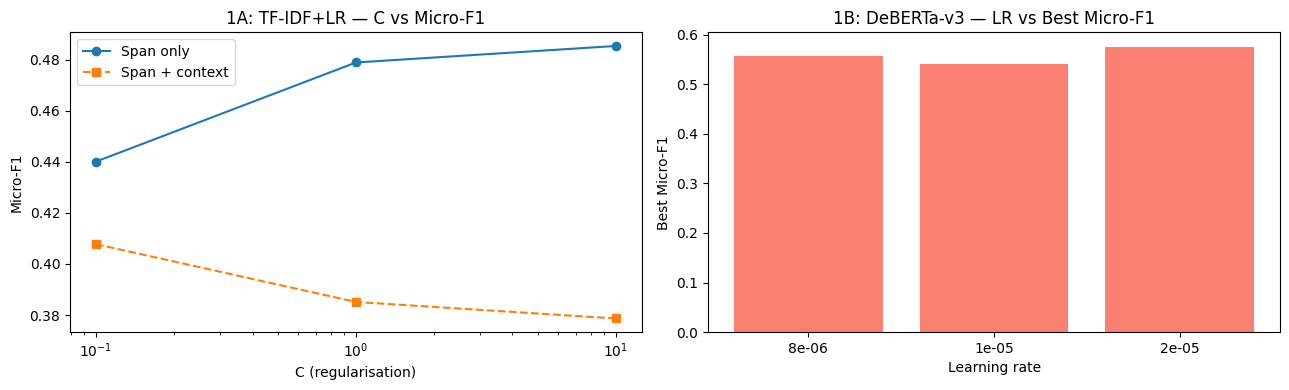

In [25]:
# ──────────────────────────────────────────────────────────────
# 4.3  Hyperparameter Impact Plots
# ──────────────────────────────────────────────────────────────

# Task 1A: C parameter vs F1 for best feature mode
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

c_vals, f1_span_only, f1_span_ctx = [], [], []
for C in [0.1, 1.0, 10.0]:
    c_vals.append(C)
    k_so  = f'span_only|ngram(1, 1)|C{C}'
    k_sc  = f'span_context|ngram(1, 1)|C{C}'
    f1_span_only.append(results_1a.get(k_so, {}).get('micro_f1', 0))
    f1_span_ctx.append(results_1a.get(k_sc, {}).get('micro_f1', 0))

axes[0].plot(c_vals, f1_span_only, 'o-', label='Span only')
axes[0].plot(c_vals, f1_span_ctx,  's--', label='Span + context')
axes[0].set_xscale('log')
axes[0].set_xlabel('C (regularisation)')
axes[0].set_ylabel('Micro-F1')
axes[0].set_title('1A: TF-IDF+LR — C vs Micro-F1')
axes[0].legend()

# Task 1B: learning rate vs best F1
lr_vals = [8e-6, 1e-5, 2e-5]
f1_by_lr = {lr: [] for lr in lr_vals}
for key, res in results_1b.items():
    lr_str = key.split('_')[0].replace('lr', '')
    lr_f   = float(lr_str)
    if lr_f in f1_by_lr:
        f1_by_lr[lr_f].append(res['micro_f1'])

axes[1].bar([str(lr) for lr in lr_vals],
            [max(f1_by_lr[lr]) if f1_by_lr[lr] else 0 for lr in lr_vals],
            color='salmon')
axes[1].set_xlabel('Learning rate')
axes[1].set_ylabel('Best Micro-F1')
axes[1].set_title('1B: DeBERTa-v3 — LR vs Best Micro-F1')

plt.tight_layout()
plt.savefig('hyperparam_plots.png', dpi=150, bbox_inches='tight')
plt.show()

---
# Appendix: Implementation Notes

## Code Credits
- HuggingFace Transformers: `AutoModelForSequenceClassification`, `AutoModelForTokenClassification` — standard fine-tuning boilerplate adapted from https://huggingface.co/docs/transformers/training
- seqeval metrics for BIO evaluation: https://github.com/chakki-works/seqeval
- Baseline TF-IDF + LR pipeline: standard sklearn pattern
- BIO alignment for subword tokenisation: adapted from HuggingFace NER tutorial

## Key Design Decisions

| Decision | Choice | Justification |
|----------|--------|---------------|
| Backbone | `roberta-base` | Balance of performance and compute; recommended by SemEval top teams |
| Input format 1B | `span [SEP] sentence` | Mirrors QA-style encoding; lets model attend jointly to span and context |
| Class weighting | Inverse-frequency | Dataset is 2:1 not_propaganda; class weight prevents model collapse |
| Max length | 256 (TC), 128 (SI) | Covers >95% of sentence lengths; SI shorter for speed |
| Gradient clipping | 1.0 | Standard for transformer fine-tuning; prevents exploding gradients |
| Warmup ratio | 10% | Linear warmup standard in BERT fine-tuning (Devlin et al., 2019) |
| BIO vs BIOES | BIO for simplicity | BIOES marginally better (newsSweeper 2020) but adds 2× output classes |
| Evaluation metric | Micro-F1 (TC), Entity-F1 (SI) | Micro-F1 standard for SemEval TC; entity-F1 requires full span match |